In [ ]:
%pip install yfinance

In [ ]:
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [ ]:
data = yf.Ticker('VNM.vn')

In [ ]:
df = data.history(period='20y')
df.tail()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2026-10-26 00:00:00+07:00,57600.0,57900.0,57500.0,57600.0,1279800,0.0,0.0
2026-10-27 00:00:00+07:00,57600.0,57900.0,57500.0,57600.0,1103400,0.0,0.0
2026-10-28 00:00:00+07:00,57700.0,58200.0,57400.0,58200.0,2362800,0.0,0.0
2026-10-29 00:00:00+07:00,58300.0,58400.0,57600.0,57700.0,1335300,0.0,0.0
2026-10-30 00:00:00+07:00,57700.0,57700.0,56700.0,56900.0,2982300,0.0,0.0


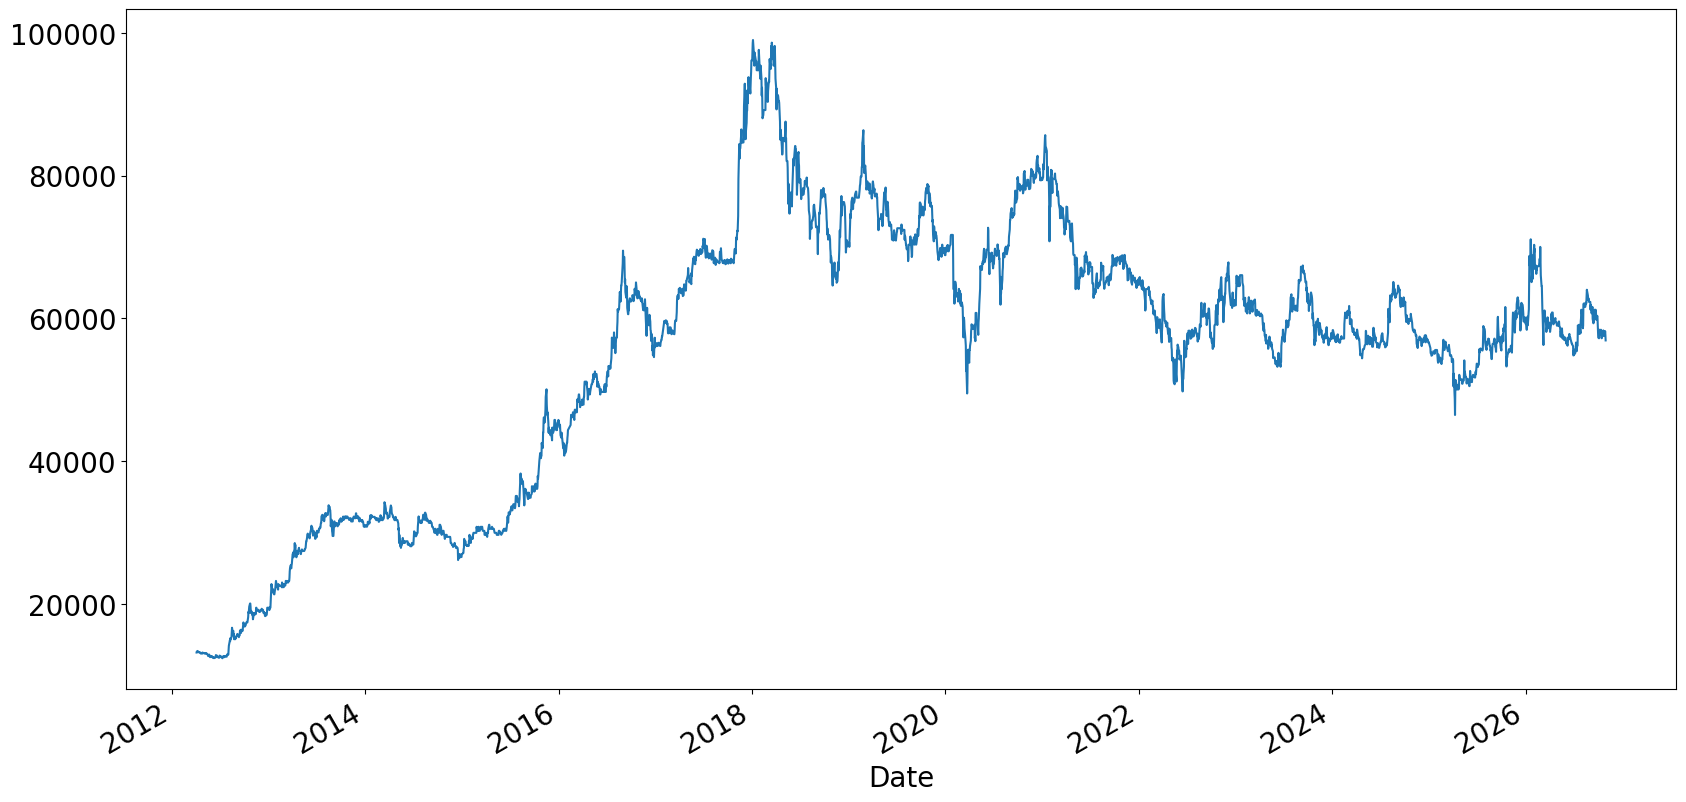

In [ ]:
plt.rcParams['figure.figsize'] = (20, 10)
plt.rcParams['font.size'] = 20
df['Close'].plot.line()
plt.show()

In [ ]:
window_size = 7
n = df.shape[0] - window_size
data = {}
for i in range(window_size):
  data[f'x{i}'] = df['Close'].values[i : n + i]
data['y'] = df['Close'].values[window_size:]
df2 = pd.DataFrame(data)
df2.head()

,x0,x1,x2,x3,x4,x5,x6,y
0,13162.100586,13162.100586,13162.100586,13379.058594,13306.736328,13234.418945,13234.418945,13234.418945
1,13162.100586,13162.100586,13379.058594,13306.736328,13234.418945,13234.418945,13234.418945,13162.099609
2,13162.100586,13379.058594,13306.736328,13234.418945,13234.418945,13234.418945,13162.099609,13162.099609
3,13379.058594,13306.736328,13234.418945,13234.418945,13234.418945,13162.099609,13162.099609,13162.099609
4,13306.736328,13234.418945,13234.418945,13234.418945,13162.099609,13162.099609,13162.099609,13162.099609


In [ ]:
X = df2.drop(columns = 'y')
y = df2['y']
X_train, X_test, y_train, y_test = train_test_split(X, y)

In [ ]:
lg = LinearRegression()
lg.fit(X_train, y_train)
lg.score(X_train, y_train), lg.score(X_test, y_test)

(0.998000404291214, 0.9975556147062812)